In [2]:
#!/usr/bin/env python
# coding: utf-8

# rdkit document
# http://rdkit.org/docs/source/rdkit.Chem.PandasTools.html

# SVGをdfに格納 matplotlibの描画確認 https://future-chem.com/rdkit-2ddraw-svg/#toc9

# 大環状分子をキレイに描画する  https://sishida21.github.io/2021/10/08/rdkit-improve-macrocycle-visualization/
# https://future-chem.com/rdkit-coordgen/


# データ前処理

## Fileを読み込み

In [2]:
# import libraries
import pandas as pd
import platform
from rdkit import rdBase
print('python version: ' + platform.python_version())
print(f'rdkit version: {rdBase.rdkitVersion}')

# ChEMBLからDLしたファイルの読み込み
df = pd.read_csv('./csv/2022TYK2.csv',sep=';',)

# None(string)を0に変換
df = df.replace('None', '0')

# datatypeを変更　　
df['MW'] = df['Molecular Weight'].astype(float)
df['pChEMBL Value'] = df['pChEMBL Value'].astype(float)
df['AlogP'] = df['AlogP'].astype(float)
df['Ligand Efficiency LLE'] = df['Ligand Efficiency LLE'].astype(float)
df['Ligand Efficiendy SEI'] = df['Ligand Efficiency SEI'].astype(float)
df['Ligand Efficiendy BEI'] = df['Ligand Efficiency BEI'].astype(float)
df['Ligand Efficiendy LE'] = df['Ligand Efficiency LE'].astype(float)
df['Document Year'] = df['Document Year'].fillna('2025').astype(int)
df['#RO5 Violations'] = df['#RO5 Violations'].astype(int)
df['Molecule Max Phase'] = df['Molecule Max Phase'].astype(str)

# SmilesカラムのNanを空に変換
df['Smiles'] = df['Smiles'].fillna('')

# 文献数
print("the number of Document ChEMBL ID is " + str(len(df['Document ChEMBL ID'].unique())))

#欠損値の数をカウント https://note.nkmk.me/python-pandas-nan-judge-count/
# print('the number of missing value is ' + str(df.isnull().sum()))

# カラムをfiltering
# df = df.filter(items=['Molecule Name', 'Molecule ChEMBL ID', 'Smiles', 'Document ChEMBL ID'])
# df.head()


python version: 3.10.6
rdkit version: 2022.03.5
the number of Document ChEMBL ID is 134


## 構造とDescriptorの発生

In [3]:
# Smiles ColumnからDataFrameに構造を追加
# https://www.macinchem.org/reviews/molsimilar/SimilarMyMolecules.html 
from rdkit.Chem import AllChem as Chem
from rdkit.Chem import PandasTools, Descriptors, Descriptors3D, QED, Draw, rdMolDescriptors, rdCoordGen
from rdkit.Chem.Draw import IPythonConsole
from rdkit import DataStructs, rdBase

# Mol Fileの追加
PandasTools.AddMoleculeColumnToFrame(df,'Smiles','Molecule_Image',includeFingerprints=True)

# Murcko Scaffoldの追加
PandasTools.AddMurckoToFrame(df, molCol='Molecule_Image', MurckoCol='Murcko_SMILES')
PandasTools.AddMurckoToFrame(df, molCol='Molecule_Image', MurckoCol='Murcko_generic_SMILES', Generic=True)
PandasTools.AddMoleculeColumnToFrame(df, molCol='Murcko_Mol', smilesCol='Murcko_SMILES')
PandasTools.AddMoleculeColumnToFrame(df, molCol='Murcko_generic_Mol', smilesCol='Murcko_generic_SMILES')
# PandasTools.FrameToGridImage(df[:8], column='Murcko_generic_Mol', legendsCol=None, molsPerRow=4)

# 骨格数情報 SMILESじゃないとなぜか反映されない
print("the number of Murcko generic scaffold is " + str(len(df['Murcko_generic_SMILES'].unique())))
print("the number of Murcko scaffold is " + str(len(df['Murcko_SMILES'].unique())))

for mol in df['Molecule_Image']:
    mol.RemoveAllConformers()
    rdCoordGen.AddCoords(mol)

for mol in df['Murcko_Mol']:
    mol.RemoveAllConformers()
    rdCoordGen.AddCoords(mol)

for mol in df['Murcko_generic_Mol']:
    mol.RemoveAllConformers()
    rdCoordGen.AddCoords(mol)

# descriptorの追加
df['TPSA'] = df['Smiles'].apply(lambda x : Descriptors.TPSA(Chem.MolFromSmiles(x)))
df['Ct HA'] = df['Smiles'].apply(lambda x : Descriptors.HeavyAtomCount(Chem.MolFromSmiles(x)))
df['Ct F'] = df['Smiles'].apply(lambda x : x.count('F'))
df['HBD'] = df['Smiles'].apply(lambda x : Descriptors.NumHDonors(Chem.MolFromSmiles(x)))
df['HBD_Ro5'] = df['Molecule_Image'].apply(lambda x : rdMolDescriptors.CalcNumLipinskiHBD(x))
df['HBA'] = df['Smiles'].apply(lambda x : Descriptors.NumHAcceptors(Chem.MolFromSmiles(x)))
df['HBA_Ro5'] = df['Molecule_Image'].apply(lambda x : rdMolDescriptors.CalcNumLipinskiHBA(x))
df['Ct RB'] = df['Smiles'].apply(lambda x : Descriptors.NumRotatableBonds(Chem.MolFromSmiles(x)))
df['Ct Ar'] = df['Smiles'].apply(lambda x : Descriptors.NumAromaticRings(Chem.MolFromSmiles(x)))
df['Fsp3'] = df['Smiles'].apply(lambda x : Descriptors.FractionCSP3(Chem.MolFromSmiles(x)))
df['QED'] = df['Molecule_Image'].apply(lambda x : QED.qed(x))

the number of Murcko generic scaffold is 419
the number of Murcko scaffold is 651


#### column index メソッド作成

In [137]:
def c_index(c_name='', data_frame=df):
    c_zip = zip(list(range(len(data_frame.columns))),data_frame.columns)
    return {key:value for key,value in c_zip if c_name in value}

## 統計量

In [17]:
dfd = df.groupby(['Document Year'])['Document ChEMBL ID'].describe()
dfg = df.groupby(['Document Year'])['Murcko_generic_SMILES'].describe()
dfm = df.groupby(['Document Year'])['Murcko_SMILES'].describe()
dfn = df.groupby(['Document Year', 'Molecule Max Phase'])['Molecule Name'].describe()

count unique                         top freq
Document Year Molecule Max Phase                                              
2002          0                      0      0                         NaN  NaN
2006          0                      0      0                         NaN  NaN
2007          0                      1      1                     TAE-684    1
2008          0                      3      3               STAUROSPORINE    1
              1                      1      1                     AST-487    1
              2                      1      1                   SU-014813    1
              4                      4      3                 TOFACITINIB    2
2009          2                      1      1                     AT-9283    1
              3                      2      1                LESTAURTINIB    2
              4                      3      2                   SUNITINIB    2
2010          0                      1      1                 JNJ-7706621    1
              4                      4      3                 TOFACITINIB    2
2011          0                      8      6               STAUROSPORINE    2
              1                      3      2                     KW-2449    2
              2                      9      7                  TOZASERTIB    2
              3                      7      4                LESTAURTINIB    2
              4                     24     14                 TOFACITINIB    4
2012          0                      0      0                         NaN  NaN
              4                      6      3                 RUXOLITINIB    3
2013          0                      0      0                         NaN  NaN
              4                     11      3                 TOFACITINIB    4
2014          0                      0      0                         NaN  NaN
              4                      8      4                 TOFACITINIB    4
2015          0                      1      1                 OCLACITINIB    1
              2                      2      2                  BMS-911543    1
              3                      2      2                 ABROCITINIB    1
              4                      2      2                  FILGOTINIB    1
2016          0                      2      2               STAUROSPORINE    1
              1                      1      1                      AC-430    1
              4                      3      3                 RUXOLITINIB    1
2017          0                      2      2  Cerdulatinib Hydrochloride    1
              1                      1      1                     CYC-116    1
              2                      3      3               SILMITASERTIB    1
              3                      3      3                 MOMELOTINIB    1
              4                      2      2                 TOFACITINIB    1
2018          0                      1      1               STAUROSPORINE    1
              4                      7      4                 TOFACITINIB    4
2019          0                      1      1               STAUROSPORINE    1
              2                      1      1                ROPSACITINIB    1
              3                      8      1             DEUCRAVACITINIB    8
              4                      8      5                 TOFACITINIB    2
2020          0                      1      1               STAUROSPORINE    1
              2                      2      2                ROPSACITINIB    1
              3                      2      2                 ABROCITINIB    1
              4                      3      1                 TOFACITINIB    3
2021          0                      0      0                         NaN  NaN
              2                      1      1                  DEFACTINIB    1
              3                      3      1             DEUCRAVACITINIB    3
              4                      4      3                  FILGOTINIB    2
2025

文献にデータが記載された分子ごとの集計値  
countは記載された回数  
uniqueは記載された文献数  
freqは1つの文献で記載された回数  
CHEMBL4435170はCHEMBL4376812に5つのデータがある

In [22]:
dfi = df.groupby(['Molecule ChEMBL ID'])['Document ChEMBL ID'].describe()
dfi[dfi['unique']>2]

,count,unique,top,freq
Molecule ChEMBL ID,,,,
CHEMBL1287853,4,3,CHEMBL1908390,2
CHEMBL1650951,3,3,CHEMBL3112442,1
CHEMBL1789941,14,11,CHEMBL2385054,3
CHEMBL2105759,6,5,CHEMBL4340527,2
CHEMBL21156,5,4,CHEMBL3621116,2
CHEMBL221959,30,25,CHEMBL2150873,2
CHEMBL2387224,5,3,CHEMBL2417497,2
CHEMBL3301607,9,6,CHEMBL3638964,4
CHEMBL3622376,3,3,CHEMBL4321787,1


#### 化合物の構造確認

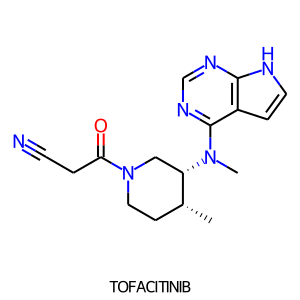

In [163]:
from rdkit.Chem import Draw
dft = df[df['Molecule ChEMBL ID']=='CHEMBL221959']
Draw.MolToImage(dft['Molecule_Image'].iloc[0], legend=dft['Molecule Name'].iloc[0])


確認

In [160]:
c_index('Year')

{42: 'Document Year'}

In [151]:
df[
    df['Molecule ChEMBL ID']=='CHEMBL4435170'
    ].iloc[:,[0,1,38,22,8,10,11]].sort_values('Document ChEMBL ID')

,Molecule ChEMBL ID,Molecule Name,Document ChEMBL ID,Assay Description,Standard Type,Standard Value,Standard Units
1326,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4330088,Inhibition of TYK2 in human Jurkat cells asses...,Ki,0.02,nM
219,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human whole blood assess...,IC50,13.00,nM
222,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human PBMC assessed as d...,IC50,2.00,nM
1006,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4376812,Allosteric inhibition of fluorescein labeled p...,IC50,0.20,nM
1274,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of fluorescein labeled probe bindin...,Ki,0.02,nM
1447,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human PBMC assessed as d...,IC50,9.00,nM
155,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4433255,Inhibition of TYK2 in human whole blood assess...,EC50,13.00,nM
1131,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4433255,Binding affinity to TYK2 pseudokinase domain (...,Ki,0.02,nM
309,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4765480,Inhibition of TYK2 in human whole blood assess...,IC50,18.00,nM
941,CHEMBL4435170,DEUCRAVACITINIB,CHEMBL4765480,Inhibition of TYK2 in IFN-alpha stimulated hum...,IC50,5.30,nM


In [154]:
c_list = [
    'Molecule Name',
    'Document ChEMBL ID',
    'Assay Description',
    'Standard Type',
    'Standard Value',
    'Standard Units',
    'Murcko_generic_SMILES'
]

dft = df[df['Molecule ChEMBL ID']=='CHEMBL4435170']
dft.loc[:, c_list].sort_values('Document ChEMBL ID')

,Molecule Name,Document ChEMBL ID,Assay Description,Standard Type,Standard Value,Standard Units,Murcko_generic_SMILES
1326,DEUCRAVACITINIB,CHEMBL4330088,Inhibition of TYK2 in human Jurkat cells asses...,Ki,0.02,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
219,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human whole blood assess...,IC50,13.00,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
222,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human PBMC assessed as d...,IC50,2.00,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
1006,DEUCRAVACITINIB,CHEMBL4376812,Allosteric inhibition of fluorescein labeled p...,IC50,0.20,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
1274,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of fluorescein labeled probe bindin...,Ki,0.02,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
1447,DEUCRAVACITINIB,CHEMBL4376812,Inhibition of TYK2 in human PBMC assessed as d...,IC50,9.00,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
155,DEUCRAVACITINIB,CHEMBL4433255,Inhibition of TYK2 in human whole blood assess...,EC50,13.00,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
1131,DEUCRAVACITINIB,CHEMBL4433255,Binding affinity to TYK2 pseudokinase domain (...,Ki,0.02,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
309,DEUCRAVACITINIB,CHEMBL4765480,Inhibition of TYK2 in human whole blood assess...,IC50,18.00,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1
941,DEUCRAVACITINIB,CHEMBL4765480,Inhibition of TYK2 in IFN-alpha stimulated hum...,IC50,5.30,nM,CC(CC1CCCC(CC2CCCC(C3CCCC3)C2)C1)C1CC1


# Plots

### Count of Documents and Scaffold by Year

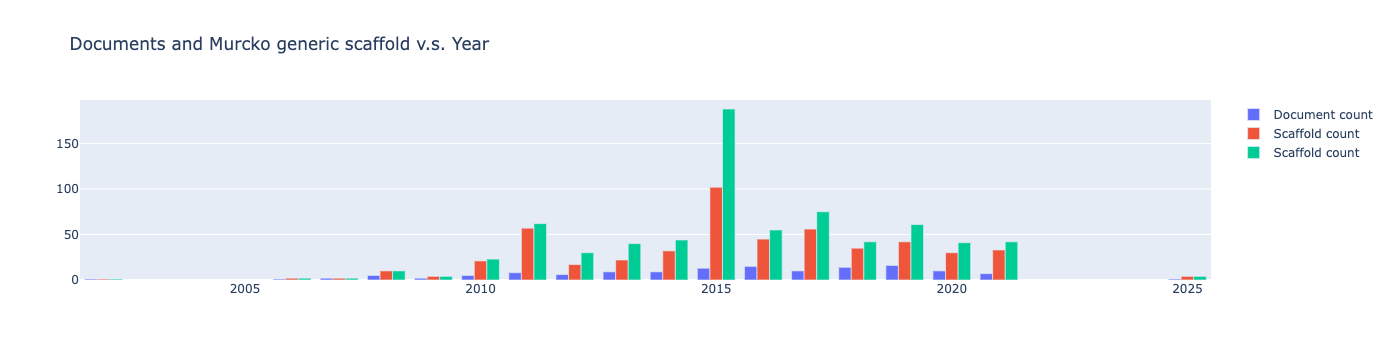

In [337]:
import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Bar(x=dfd.index, y=dfd['unique'], name='Document count'))
fig.add_trace(go.Bar(x=dfg.index, y=dfg['unique'], name='Scaffold count'))
fig.add_trace(go.Bar(x=dfm.index, y=dfm['unique'], name='Scaffold count'))

fig.update_layout(
    title='Documents and Murcko scaffold v.s. Year',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    barmode='group',
)
fig.show()

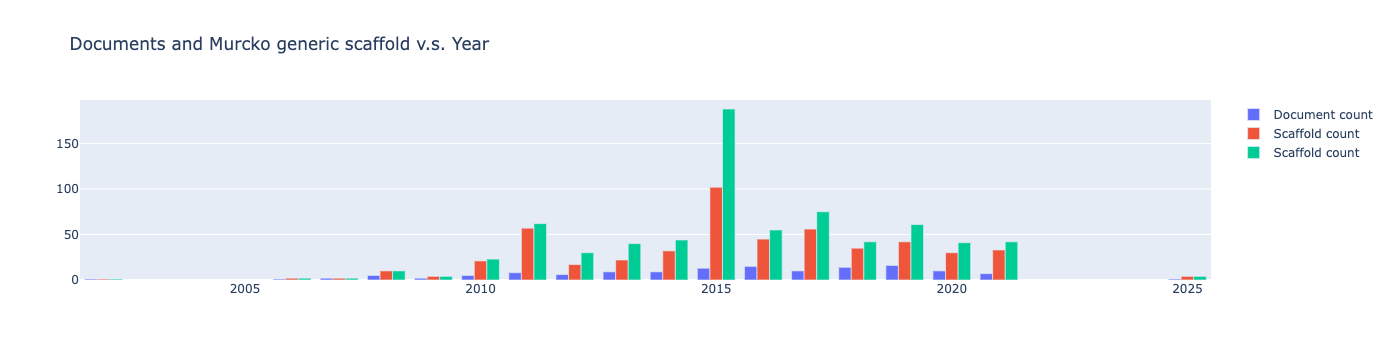

In [ ]:
import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Bar(x=dfd.index, y=dfd['unique'], name='Document count'))
fig.add_trace(go.Bar(x=dfg.index, y=dfg['unique'], name='Scaffold count'))
fig.add_trace(go.Bar(x=dfm.index, y=dfm['unique'], name='Scaffold count'))

fig.update_layout(
    title='Documents and Murcko scaffold v.s. Year',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    barmode='stack',
)
fig.show()

### pChEMBL Value box by Year

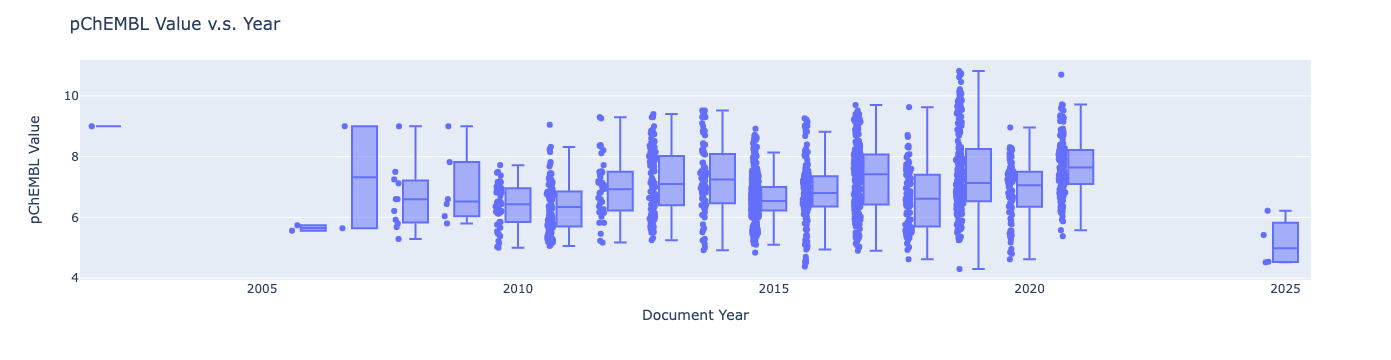

In [339]:
import plotly.express as px
fig = px.box(
    df,
    x='Document Year',
    y='pChEMBL Value',
    points='all',
)
fig.update_layout(
    title='pChEMBL Value v.s. Year',
    showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    ) 
fig.show()

### Filtering off by Molecule Name

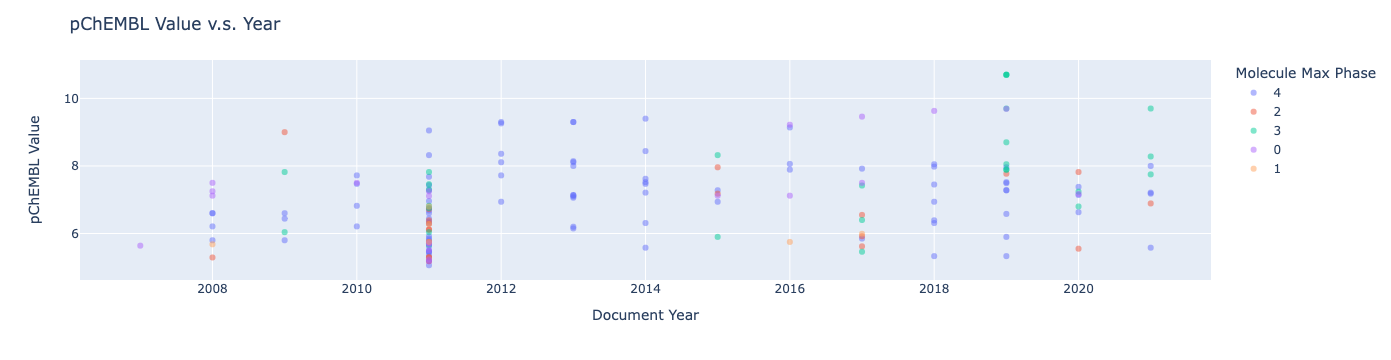

In [348]:
import plotly.express as px
fig = px.scatter(
    df[df['Molecule Name'].notna()],
    x='Document Year',
    y='pChEMBL Value',
    color='Molecule Max Phase',
    # color='Document ChEMBL ID',
    # color='Murcko_generic_SMILES',
    # size='AlogP',
    hover_name='Molecule Name',
    # hover_data=['Document ChEMBL ID', df[df['Molecule Name'].notna()].index],
    opacity=0.5
)
fig.update_layout(
    title='pChEMBL Value v.s. Year',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    ) 
fig.show()


### Summary Table of Specific Molecule

##### Molecule IDで検索

,Molecule Name,Molecule ChEMBL ID,Molecule_Image,Molecular Weight,pChEMBL Value,AlogP,Ligand Efficiency LLE,#RO5 Violations,Assay Description,Document ChEMBL ID
1326,DEUCRAVACITINIB,CHEMBL4435170,,425.47,10.7,1.73,8.97,0,Inhibition of TYK2 in human Jurkat cells asses...,CHEMBL4330088

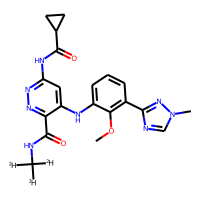

In [3]:
MolID = input('index?') # 1326
df[int(MolID):int(MolID)+1].filter(items=[
    'Molecule Name', 
    'Molecule ChEMBL ID',
    'Molecule_Image',
    'Molecular Weight',
    'pChEMBL Value',
    'AlogP',
    'Ligand Efficiency LLE',
    '#RO5 Violations',
    'Assay Description',
    'Document ChEMBL ID'
])

#### Molecule Nameで検索

,Molecule Name,Molecule ChEMBL ID,Molecule_Image,Molecular Weight,pChEMBL Value,AlogP,Ligand Efficiency LLE,#RO5 Violations,Assay Description,Document ChEMBL ID
155,DEUCRAVACITINIB,CHEMBL4435170,,425.47,7.89,1.73,6.16,0,Inhibition of TYK2 in human whole blood assess...,CHEMBL4433255

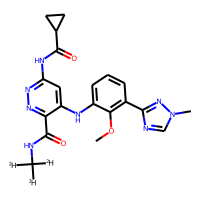

In [350]:
name = input('Molecule Name?') #DEUCRAVACITINIB
df[df['Molecule Name']==name].filter(items=[
    'Molecule Name', 
    'Molecule ChEMBL ID',
    'Molecule_Image',
    'Molecular Weight',
    'pChEMBL Value',
    'AlogP',
    'Ligand Efficiency LLE',
    '#RO5 Violations',
    'Assay Description',
    'Document ChEMBL ID'
]).head(1)


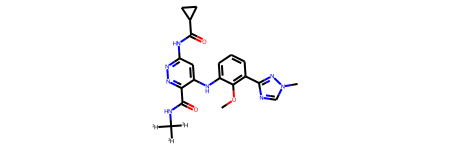

In [15]:
df['Molecule_Image'].iloc[155]

### SMILESに変換

In [5]:
Chem.MolToSmiles(df['Molecule_Image'].iloc[155])

'[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc1cccc(-c2ncn(C)n2)c1OC'

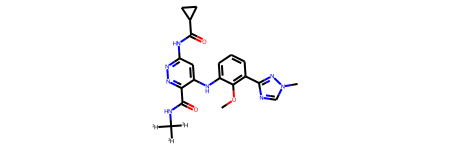

In [6]:
Chem.MolFromSmiles('[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc1cccc(-c2ncn(C)n2)c1OC')

#### SMILESで検索

In [6]:
smiles = input('Smiles?') #c1ccc(c(c1)C(=O)Nc2ccnc(c2)NC(=O)C3CC3)Cl
df[df['Smiles']==smiles].filter(items=[
    'Molecule Name', 
    'Molecule ChEMBL ID',
    'Molecule_Image',
    'Molecular Weight',
    'pChEMBL Value',
    'AlogP',
    'Ligand Efficiency LLE',
    '#RO5 Violations',
    'Assay Description',
    'Document ChEMBL ID'
]).head(1)


,Molecule Name,Molecule ChEMBL ID,Molecule_Image,Molecular Weight,pChEMBL Value,AlogP,Ligand Efficiency LLE,#RO5 Violations,Assay Description,Document ChEMBL ID


### matplotlib

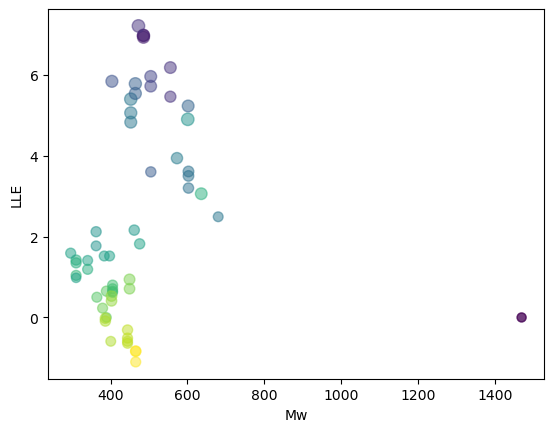

In [4]:
import matplotlib.pyplot as plt
import numpy as np
# Document ChEMBL IDでfiltering
# ddf = df[df['Document ChEMBL ID']=='CHEMBL4622984'].dropna(subset=['Ligand Efficiency LLE', 'Molecular Weight', 'pChEMBL Value'])

# %%
fig, ax = plt.subplots()
# ax.set_xticks([400, 600, 800])
ax.scatter(x=df['Molecular Weight'], 
            y=df['Ligand Efficiency LLE'].replace('','0'), 
            alpha=0.5,
            s=df['pChEMBL Value'] *10,
            c=df['AlogP']
            )
ax.set_xlabel("Mw")
ax.set_ylabel("LLE")
# ax.set_xlim([400,800])
plt.show()


### Plotly.go scatter

In [180]:
import plotly.graph_objects as go

data1 = go.Scatter(x=df['Molecular Weight'], 
                    y=df['pChEMBL Value'],
                    mode='markers',
                    # fill='Murcko_generic_SMILES'
                    )
go.Figure(data1)


### Plotly.px scatter

In [181]:
import plotly.express as px
fig = px.scatter(df,
    x='Molecular Weight',
    y='Ligand Efficiency LLE',
    color='Molecule Max Phase',
    # color='AlogP',
    # color='Document ChEMBL ID',
    # color='Murcko_generic_SMILES',
    # size='pChEMBL Value',
    hover_name='Molecule ChEMBL ID',
    hover_data=['Document ChEMBL ID', df.index],
    opacity=0.5
)
fig.update_layout(
    title='LLE v.s. MW',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
) 
fig.show()


### Plotly.3D scatter

In [50]:
import plotly.express as px
fig = px.scatter_3d(df,
                    x='Molecular Weight',
                    z='pChEMBL Value',
                    y='AlogP',
                    color='Document ChEMBL ID',
                    # color='Murcko_generic_SMILES',
                    # size='pChEMBL Value',
                    hover_name='Molecule ChEMBL ID',
                    hover_data=['Molecule ChEMBL ID',df.index],
                    opacity=0.5)
fig.update_layout(
    # showlegend=False, # Legendのon/off
    width=1200,
    height=1000
    ) 
fig.show()

### Plotly.violin

In [35]:
fig = px.violin(df,
                x='Document ChEMBL ID',
                y='Ligand Efficiency LLE',
                color='Document ChEMBL ID',
                box=True,
                points='all',
                hover_data=['Molecular Weight', 'AlogP', 'pChEMBL Value']
                )
fig.update_layout(
    title='pValue v.s. Document ChEMBL ID',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    ) 

fig.show()

### Plotly.box

In [182]:
fig = px.box(df,
                y='Ligand Efficiency LLE',
                x='Document ChEMBL ID',
                color='Document ChEMBL ID',
                points='all',
                hover_data=['Molecular Weight', 'AlogP', 'pChEMBL Value', df.index]
                )
fig.update_layout(
    title='LLE v.s. Document ChEMBL ID',
    # showlegend=False, # Legendのon/off
    width=1000,
    # height=700
    ) 

fig.show()

### matplotlib.mouseover

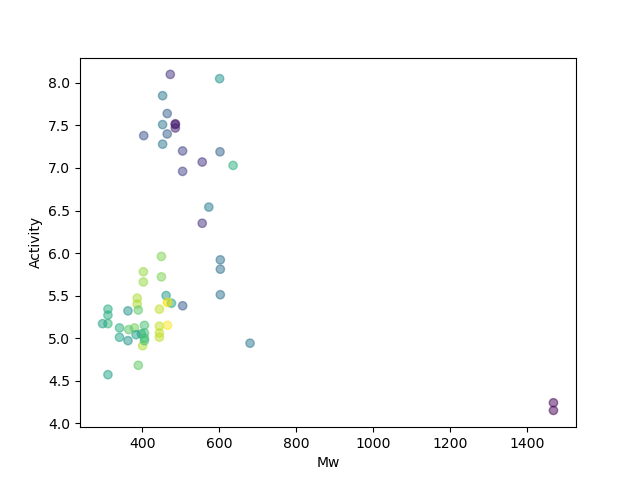

In [8]:
# https://choron81.hatenablog.com/entry/2022/11/30/000000
import matplotlib.pyplot as plt
%matplotlib widget
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

mols = [Chem.MolFromSmiles(Smile) for Smile in df["Smiles"]]
ims=[Draw.MolToImage(mol) for mol in mols]

# %%
fig, ax = plt.subplots()
imagebox = OffsetImage(ims[0], zoom=0.3)
imagebox.image.axes = ax

annot = AnnotationBbox(imagebox,
                       xy=(0,0),
                       xybox=(60,-60),
                       xycoords="data",
                       boxcoords="offset points",
                       pad=0.5,
                       arrowprops=dict( arrowstyle="->"))
annot.set_visible(False)
ax.add_artist(annot)
    
x = df["Molecular Weight"]#x軸は分子量。
y = df["pChEMBL Value"]#y軸は活性値。
colors = df["AlogP"]#色はAlogP。
sc = plt.scatter(x, y, c=colors, alpha=0.5)

def update_annot(ind):
    i = ind["ind"][0]
    pos = sc.get_offsets()[i]
    annot.xy = (pos[0], pos[1])
    imagebox.set_data(ims[i])

def hover(event):
    vis = annot.get_visible()
    if event.inaxes == ax:
        cont, ind = sc.contains(event)
        if cont:
            update_annot(ind)
            annot.set_visible(True)
            fig.canvas.draw_idle()
        else:
            if vis:
                annot.set_visible(False)
                fig.canvas.draw_idle()

fig.canvas.mpl_connect("motion_notify_event", hover)

ax.set_xlabel("Mw")
ax.set_ylabel("Activity")
# plt.yscale('log')#y軸は対数軸にした。

# fig.colorbar(sc, ax=ax)#カラーバーを付けた。

plt.show()



# Drawing molecules

In [8]:
df[df['Molecule Name']=='DEUCRAVACITINIB']

,Molecule ChEMBL ID,Molecule Name,Molecule Max Phase,Molecular Weight,#RO5 Violations,AlogP,Compound Key,Smiles,Standard Type,Standard Relation,...,Ct HA,Ct F,HBD,HBD_Ro5,HBA,HBA_Ro5,Ct RB,Ct Ar,Fsp3,QED
155,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,EC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
219,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,11; BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
222,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,11; BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
309,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,6; BMS-686165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
941,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,6; BMS-686165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
1006,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,11; BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
1131,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,Ki,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
1205,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,6; BMS-686165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,IC50,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
1274,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,11; BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,Ki,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413
1326,CHEMBL4435170,DEUCRAVACITINIB,3,425.47,0,1.73,BMS-986165,[2H]C([2H])([2H])NC(=O)c1nnc(NC(=O)C2CC2)cc1Nc...,Ki,'=',...,31,0,3,3,9,11,8,3,0.3,0.496413


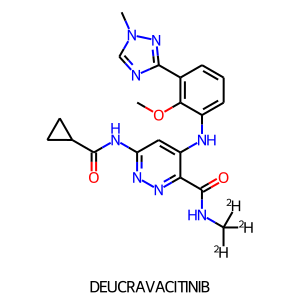

In [162]:
Cn = input('Molecule index?') # 155
Draw.MolToImage(df['Molecule_Image'].iloc[int(Cn)], legend=df['Molecule Name'].iloc[int(Cn)])

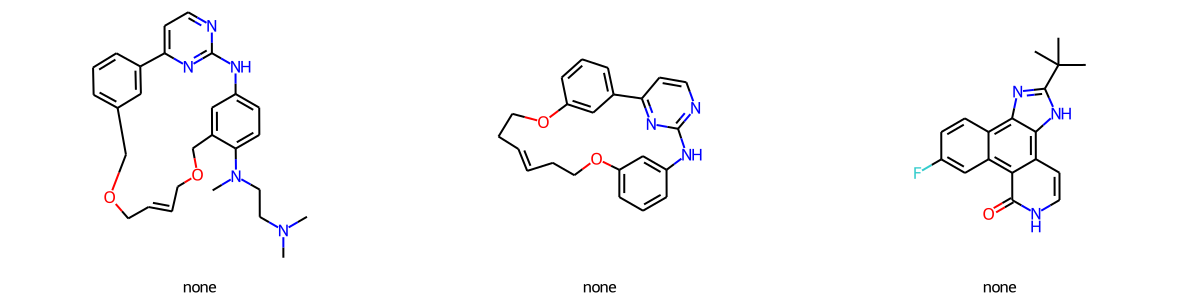

In [29]:
Draw.MolsToGridImage(df['Molecule_Image'].iloc[0:3],
                        molsPerRow=3,
                        subImgSize=(400,300),
                        legends=list(df['Molecule Name'].fillna('none'))
                        )

### Filtering by Document ChEMBLE ID

In [18]:
# filtering with Document ChEMBLE ID CHEMBL2176955
DocID = input('Document ChEMBL ID?')
ddf = df[df['Document ChEMBL ID']==DocID]

### Viewing top 3 compounds

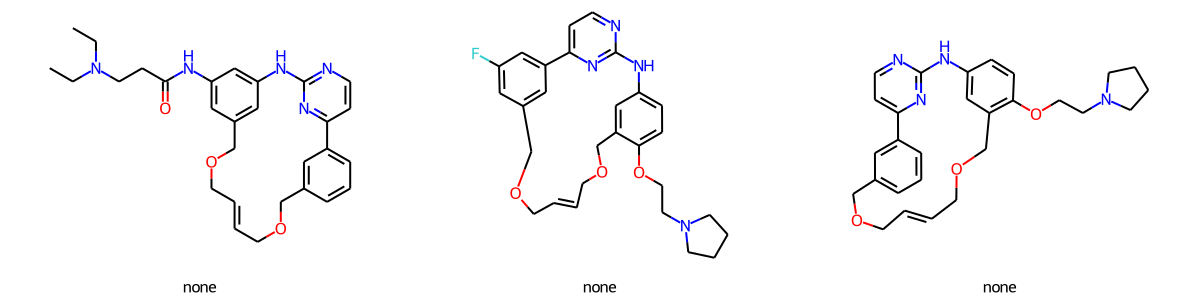

In [22]:
Draw.MolsToGridImage(ddf.sort_values('pChEMBL Value', ascending=False)['Molecule_Image'].iloc[0:3],
                        molsPerRow=3,
                        subImgSize=(400,300),
                        legends=list(ddf['Molecule Name'].fillna('none'))
                        )

### show summary table

,Molecule Name,Molecule ChEMBL ID,Molecule_Image,pChEMBL Value,AlogP,#RO5 Violations,Assay Description,Document ChEMBL ID
0,NaN,CHEMBL2181327,,7.15,4.49,0,Inhibition of recombinant TYK2,CHEMBL2176955
1,NaN,CHEMBL2181315,,5.28,4.99,0,Inhibition of recombinant TYK2,CHEMBL2176955
16,NaN,CHEMBL2181322,,6.85,3.90,0,Inhibition of recombinant TYK2,CHEMBL2176955

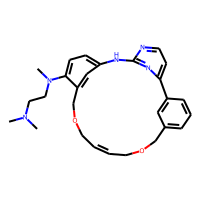
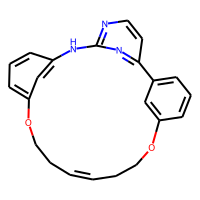
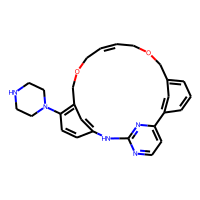

In [185]:
ddf.filter(items=['Molecule Name', 
    'Molecule ChEMBL ID',
    'Molecule_Image',
    'Moleculer Weight',
    'pChEMBL Value',
    'AlogP',
    'Ligand effieicncy LLE',
    '#RO5 Violations',
    'Assay Description',
    'Document ChEMBL ID'
]).head(3)


### Save summary csv

In [145]:
ddf.filter(items=['Molecule Name', 
                 'Molecule ChEMBL ID',
                 'Smiles',
                 'Moleculer Weight',
                 'pChEMBL Value',
                 'AlogP',
                 'Ligand effieicncy LLE',
                 '#RO5 Violations',
                 'Assay Description',
                 'Document ChEMBL ID'
                 ]).to_csv('test2.csv')


### Plotly.scatter

In [186]:
import plotly.express as px
fig = px.scatter(ddf,
                    x='Molecular Weight',
                    y='Ligand Efficiency LLE',
                    # color='AlogP',
                    color='Murcko_SMILES',
                    # color='Murcko_generic_SMILES',
                    # size='pChEMBL Value',
                    hover_name='Molecule ChEMBL ID',
                    hover_data=['Murcko_SMILES', ddf.index],
                    opacity=0.5
                )
fig.update_layout(
    title='LLE v.s. MW',
    # showlegend=False, # Legendのon/off
    width=1400,
    # height=700
    ) 
fig.show()


### Plotly.box

In [187]:
fig = px.box(ddf,
                x='Ligand Efficiency LLE',
                y='Murcko_SMILES',
                color='Murcko_SMILES',
                points='all',
                hover_data=['Molecular Weight', 'AlogP', 'pChEMBL Value', ddf.index]
                )
fig.update_layout(
    title='LLE v.s. Document ChEMBL ID',
    showlegend=False, # Legendのon/off
    width=1600,
    # height=800
    ) 

fig.show()

##### PMI plot

In [298]:
# 立体構造の追加
ddf['AddHs'] = ddf['Molecule_Image'].apply(lambda x : AllChem.AddHs(x))
ddf['3D'] = ddf['AddHs'].apply(lambda x : AllChem.EmbedMolecule(x, AllChem.ETKDGv3()))
ddf['3D'] = ddf['AddHs'].apply(lambda x : AllChem.RemoveHs(x))
ddf['NPR1'] = ddf['AddHs'].apply(lambda x : Descriptors3D.NPR1(x))
ddf['NPR2'] = ddf['AddHs'].apply(lambda x : Descriptors3D.NPR2(x))
ddf['Molecule Max Phase'] = ddf['Molecule Max Phase'].astype(str)

import plotly.express as px
fig = px.scatter(ddf,
    x='NPR1',
    y='NPR2',
    color='Molecule Max Phase',
    # color='AlogP',
    # color='Document ChEMBL ID',
    # color='Murcko_generic_SMILES',
    # size='pChEMBL Value',
    # hover_name='Molecule ChEMBL ID',
    # hover_data=['Document ChEMBL ID', df.index],
    opacity=0.5
)
fig.update_layout(
    title='PMI plot',
    # showlegend=False, # Legendのon/off
    width=700,
    # height=700,
    xaxis=dict(range= (0,1)),
    yaxis=dict(range= (0.5,1))
) 
fig.show()


##### add pdb id
##### pymol

In [7]:
export DISPLAY=:0

SyntaxError: invalid syntax (1385392805.py, line 1)

In [6]:
from pymol import cmd
pymol.cmd.fetch("1alk", type="mmtf")
pymol.cmd.hide("everything")
pymol.cmd.select("sel1",  "byres resn * within 5 of (resn PO4 and chain A)")
pymol.cmd.zoom("sel1")
pymol.cmd.show_as("sticks", "sel1")
pymol

ExecutiveWindowZoom-Warning: selection doesn't specify any coordinates.


<module 'pymol' from '/Users/keetane/opt/anaconda3/envs/pymol/lib/python3.10/site-packages/pymol/__init__.py'>

# PyGWalker

In [3]:
import pygwalker as pyg
gwalker = pyg.walk(df)